In [1]:
from dotenv import load_dotenv
from pydantic import BaseModel, Field

from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage

from typing import TypedDict, Literal, Optional, Annotated

from langgraph.graph import StateGraph, START, END

In [2]:
load_dotenv()

True

In [3]:
# Creating schema for evaluation

class EvaluationSchema(BaseModel):

    evaluation: Annotated[Literal['approved', 'needs_improvement'], Field(description = 'Final evaluation result')]
    feedback: Annotated[str, Field(description = "Feedback for the tweet if not approved")]

In [41]:
# Creating LLMs

generator_model = ChatGoogleGenerativeAI(model = 'gemini-2.5-flash')
evaluator_model = ChatGoogleGenerativeAI(model = 'gemini-2.5-flash')
optimizer_model = ChatGoogleGenerativeAI(model = 'gemini-2.5-flash')

# Structured evaluation model
evaluator_model = evaluator_model.with_structured_output(EvaluationSchema)

In [ ]:
# Creating State

class TweetState(TypedDict):

    topic: str
    tweet: str
    evaluation: Literal['approved', 'needs_improvemet']
    feedback: str
    iteration: int
    max_iteration: int

# evaluation model will evaluate and also give feedback if not approved
# max_iteration for breaking if stuck in an infinite loop.

In [49]:
# Defining nodes (Funations)

def generate_tweet(state: TweetState) -> TweetState:
    
    # creating the prompt
    messages = [SystemMessage(content = "You are an funny and cleaver twitter/X influencer."),
               HumanMessage(content = f'''
               Write a short, original and hilarous tweet on "{state['topic']}". Folow bellow given rules.
               
               Rules:
               - Do not use queation-answer format.
               - Do not exceed 300 characters.
               - Use irony, sarcasm and humor considering the given topic.
               - Think in meme logic and punchlines.
               - Use simple day-to-day english.
               ''')
               ]

    # invoke generator_model
    response = generator_model.invoke(messages).content

    # update response
    return {'tweet': response}


In [50]:
# Defining evaluation function
def evaluate_tweet(state: TweetState) -> TweetState:

    # prompt
    messages = [
        SystemMessage(content = "You are a ruthless tweeter critic. You evaluate tweets based on originality, virality and tweet format."),
        HumanMessage(content = f'''
        Evaluate the following tweet:
    
        Tweet: "{state['tweet']}"
        
        Use the criteria below to evaluate the tweet:
        1. Originality – Is this fresh, or have you seen it a many times before?  
        2. Humor – Did it genuinely make you smile, laugh, or chuckle?  
        3. Punchiness – Is it short, sharp, and scroll-stopping?  
        4. Virality Potential – Would people retweet or share it?  
        5. Format – Is it a well-formed tweet (not a setup-punchline joke, not a Q&A joke, and under 300 characters)?
        
        Auto-reject if:
        - It's written in question-answer format (e.g., "Why did..." or "What happens when...")
        - It exceeds 300 characters
        - It reads like a traditional setup-punchline joke
        - Dont end with generic, throwaway, or deflating lines that weaken the humor (e.g., “Masterpieces of the auntie-uncle universe” or vague summaries)
        
        ### Respond ONLY in structured format:
        - evaluation: "approved" or "needs_improvement"  
        - feedback: One paragraph explaining the strengths and weaknesses 
            ''')
    ]

    # Invoking evaluator_model
    response = evaluator_model.invoke(messages)

    # update states
    return {"evaluation": response.evaluation, "feedback": response.feedback}

In [66]:
# Defining optimizer function

def optimize_tweet(state: TweetState) -> TweetState:

    messages = [
        SystemMessage(content = "You re-generate tweets for virality and humor based on given feedback."),
        HumanMessage(content = f'''
        Improve the tweet based on below given feedback.
        Feedback: {state['feedback']}
        Topic: {state['topic']}
        Original tweet: state['tweet']

        Follow below given rules while optimizing the tweet.

        Rules:
               - Do not use queation-answer format.
               - Do not exceed 300 characters.
               - Use irony, sarcasm and humor considering the given topic.
               - Think in meme logic and punchlines.
               - Use simple day-to-day english.    
        ''')
    ]

    response = optimizer_model.invoke(messages).content
    iteration = state['iteration'] + 1

    return {'tweet': response, 'iteration': iteration}


In [67]:
# Defining the condition for iteration

def iter_condition(state: TweetState) -> TweetState:

    if state['evaluation'] == 'approved' or state['iteration'] >= state['max_iteration']:
        return "approved"

    else:
        return "needs_improvement"

In [68]:
# Creating a graph
graph = StateGraph(TweetState)

# Add nodes
graph.add_node('generate_tweet', generate_tweet)
graph.add_node('evaluate_tweet', evaluate_tweet)
graph.add_node('optimize_tweet', optimize_tweet)
graph.add_node('iter_condition', iter_condition)


# create edges
graph.add_edge(START, 'generate_tweet')
graph.add_edge('generate_tweet', 'evaluate_tweet')
graph.add_conditional_edges('evaluate_tweet', iter_condition, {'approved': END, 'needs_improvement': 'optimize_tweet'})
graph.add_edge('optimize_tweet', 'evaluate_tweet')

workflow = graph.compile()

In [71]:
initial_state = {
    "topic": "Politicians in 500 Characters",
    "iteration": 1,
    "max_iteration": 5
}

response = workflow.invoke(initial_state)

In [72]:
response

{'topic': 'Politicians in 500 Characters',
 'tweet': 'Politicians: Masters of saying "We hear you!" while simultaneously adjusting their monocle and approving another pay raise. Their commitment to the people is as strong as my New Year\'s gym resolution. Truly inspiring. ✨ #PoliticalHumor #OutOfTouch',
 'evaluation': 'approved',
 'feedback': 'This tweet is well-crafted, demonstrating strong originality through its vivid imagery, such as "adjusting their monocle," and a relatable, humorous comparison to a "New Year\'s gym resolution." It genuinely evokes a chuckle, making it highly effective in its humor. The tweet is punchy and scroll-stopping, delivering its satirical message efficiently without being overly verbose. Its relatability and sharp wit give it excellent virality potential, as it addresses a common frustration with politicians in a fresh way. Furthermore, the format is impeccable, adhering to character limits and avoiding common pitfalls like Q&A or setup-punchline structu

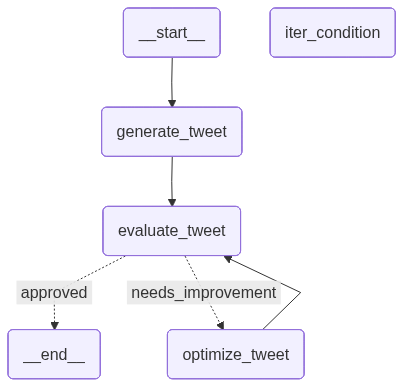

In [74]:
workflow